In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

hbar = 1.0

# Temas Selectos de Física Atómica I
## Actividad 3. Estudio Numérico de un Potenical Unidimensional
 Ángel André Aguilar Contreras

In [2]:
class potential: # Definimos una clase para guardar los potenicales
    def harmonic_oscillator(x, m, omega): # Potencial de un oscilador armónico
        V = 0.5*m*(omega**2)*(x**2) # V(x) = 1/2 m w^2 x^2
        return V
    def double_well(x, a, lamda): # Potencial de un doble pozo
        V = lamda*(x**2 - a**2)**2 # V(x) = lambda(x^2 - a^2)^2
        return V

In [3]:
class plot:
    def heatmap(H):
        """
        1b. Graficar la matriz en un apa de color para visualizar los elementos relevantes. 
        """
        fig = plt.figure(figsize=(6, 6))
        im = plt.imshow(H, cmap='inferno', aspect='equal')
        fig.colorbar(im, fraction=0.046, pad=0.04, label="Energía")
        plt.title('Heatmap de la Matriz Hamiltoniana')
        plt.xlabel('Columna [Índice i]')
        plt.ylabel('Fila [Índice j]')
        plt.show()
        
    def solution(x, V, E, f, **kargs):
        """
        3. Grafique las funciones de onda y las energías del sistema. Como mínimo, utilice los primeros 5 estados.
        """
        n, label, L = kargs.get('n', 5), kargs.get('label', ''), kargs.get('L', 1)
        
        plt.figure(figsize=(9, 6))
        plt.plot(x, V, label= 'V(X)', color='black', linestyle='--', linewidth=1, alpha=0.8)
        for i in range(n):
            (line,) = plt.plot(x, f[:, i]**2 + E[i], label = f'n = {i}, E = {E[i]:.4f}') 
            color = line.get_color()
            plt.hlines(E[i], x[0], x[-1], color = color, linestyle=':', alpha=0.5)

        plt.xlim(-L, L)
        plt.ylim(-0.1, max(f[:,n] + E[n])+0.1)
        
        plt.xlabel('Posicion [x]')
        plt.ylabel('Energias y norma de las funciones de onda')
        plt.title(f'Soluciones a Potencial Unidimensional ({label})')
        plt.legend()
        plt.grid()
        plt.tight_layout()
        plt.show()

In [4]:
class solve:
    def hamiltonian(dx, V):
        """
        Resuelve la matriz del Hamiltoniano considerando la parte cinética y la parte potencial.
        Calculamos la parte cinética del Hamiltoniano a partir de diferencias finitas centradas.
        d^2(Psi)/dx^2 \approx (Psi_{i+1} - 2 Psi_{i} + Psi_{i-1})/(delta x^2)
        """

        """ 1a. Crear la matriz para emplearla en la ecuación de Schrodinger discretizada. """
        constant = -hbar**2 / (2 * m * dx**2) # constante fuera del diferencial -h^2/2m 1/dx^2
        main_diag = -2*np.ones(N) # multiplicado por -2 sobre la diagonal
        off_diag = np.ones(N-1) # multiplicado por 1 en las secundarias
        T = constant*(np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1))
        H = T + np.diag(V) # Hamiltoniano
        """ 1b. Graficar la matriz en un mapa de color para visualizar los elementos relevantes. """
        plot.heatmap(H) # Graficación de la Matriz Hamiltoniana
        """ 2a. Utilice herramientas numéricas de algebra lineal para resolver la ecuación de eigenvalores. """
        eigenvalues, eigenfunctions = eigh(H)
        """ 2b. Normalice las eigenfunciones calculadas. """
        # Norma con la regla del Trapecio (para realizar una mejor normalización)
        norm = np.trapezoid(eigenfunctions**2, x, axis=0) 
        eigenfunctions /= np.sqrt(norm) # Normalización de las funciones de onda 
        return eigenvalues, eigenfunctions

:::   Solución al Potencial del Oscilador Armónico   :::


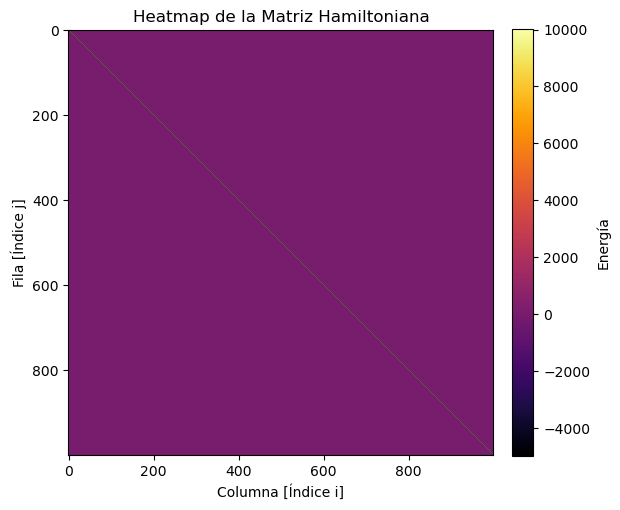

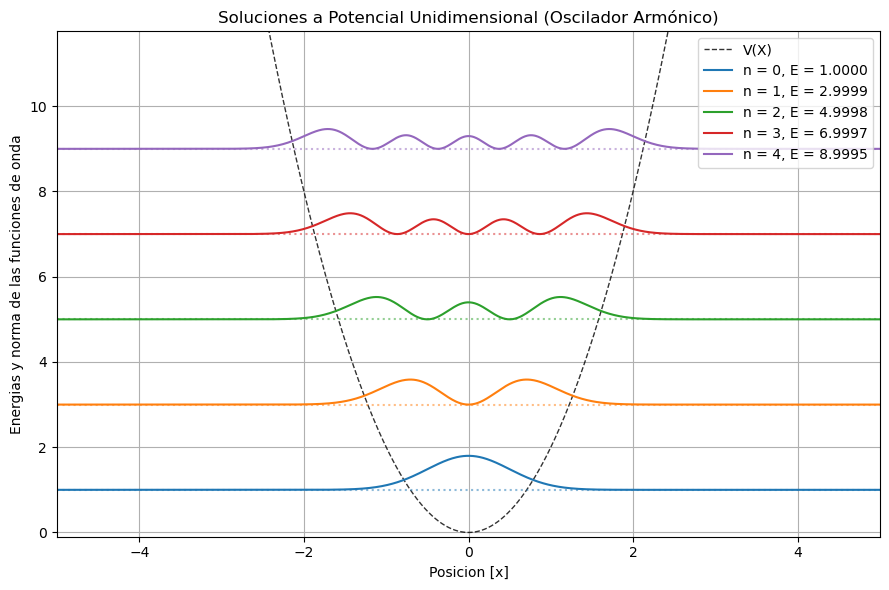

In [5]:
"""
Oscilador Armónico
"""
# Variables de Simulación
L = 5.0
N = 1000

# Variables del Potencial (Oscilador Armónico)
m = 1.0
omega = 2.0

#Simulación
print(":::   Solución al Potencial del Oscilador Armónico   :::")
x = np.linspace(-L, L, N)
dx = x[1]- x[0]
V = potential.harmonic_oscillator(x, m = m , omega = omega)
energies, wavefunctions = solve.hamiltonian(dx, V)
plot.solution(x, V, energies, wavefunctions, n = 5, L = L, label = "Oscilador Armónico")


:::   Solución al Potencial de Doble Pozo   :::


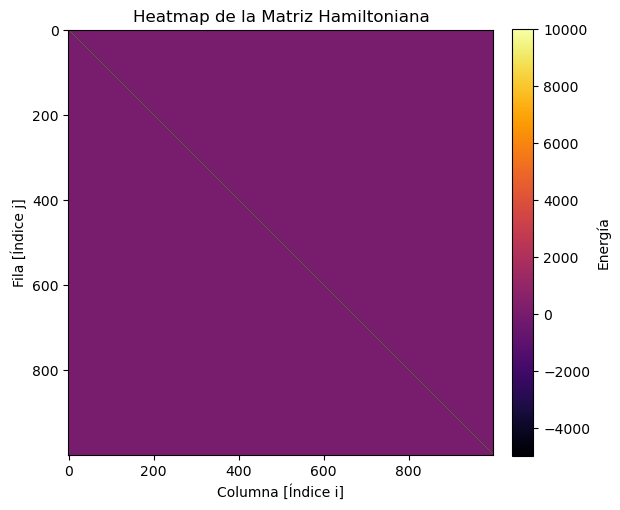

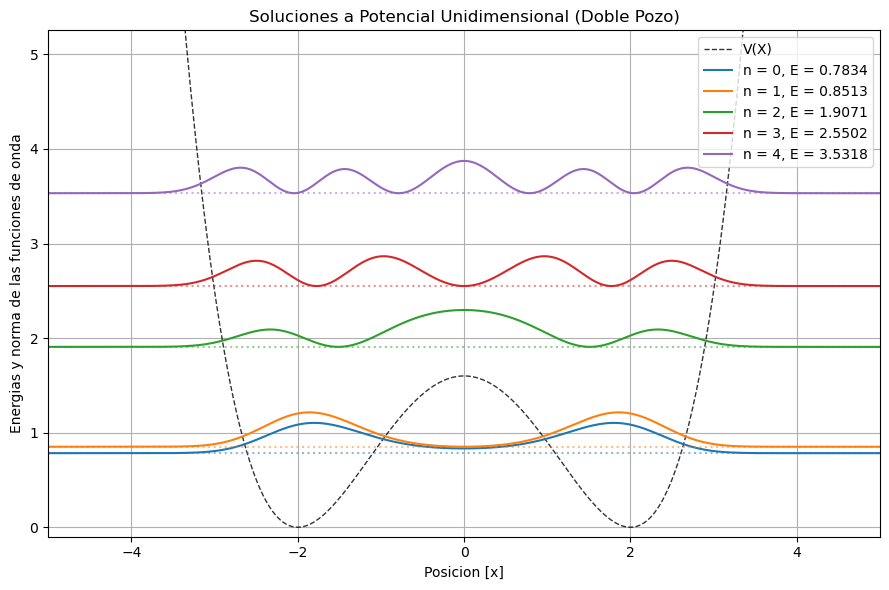

In [6]:
"""
Doble Pozo
"""
# Variables de Simulación
L = 5.0
N = 1000

# Variables del Potencial (Oscilador Armónico)
a = 2.0
lamda = 0.1

#Simulación
print(":::   Solución al Potencial de Doble Pozo   :::")
x = np.linspace(-L, L, N)
dx = x[1]- x[0]
V = potential.double_well(x, a = a , lamda = lamda)
energies, wavefunctions = solve.hamiltonian(dx, V)
plot.solution(x, V, energies, wavefunctions, n = 5, L = L, label = "Doble Pozo")